In [1]:
import math
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pax = duckdb.sql("""
    -- слабая идентификация: известны только по посадочным талонам (группировка по имени) или только по документам
    select passenger_id, n_trips, boarding_pass_only or document_only as weak
    from 'output/dim_passenger.parquet'
""").df()
print(f"пассажиров всего: {len(pax):,}, без полётов: {(pax.n_trips == 0).sum():,}")
pax = pax[pax.n_trips > 0]
pax.groupby('weak').n_trips.describe()

пассажиров всего: 126,191, без полётов: 9,438


,count,mean,std,min,25%,50%,75%,max
weak,,,,,,,,
False,95215.0,19.659339,4.273696,4.0,17.0,20.0,22.0,42.0
True,21538.0,5.888430,8.070310,1.0,1.0,2.0,5.0,65.0


In [2]:
dist = (pax.assign(group=np.where(pax.weak, 'tickets', 'profile'))
           .pivot_table(index='n_trips', columns='group', values='passenger_id', aggfunc='count', fill_value=0)
           .reindex(range(1, pax.n_trips.max() + 1), fill_value=0))

prof = pax.loc[~pax.weak, 'n_trips']
N, lam, sd = len(prof), prof.mean(), prof.std()
k = dist.index.to_numpy()
dist['poisson'] = [N * math.exp(x * math.log(lam) - lam - math.lgamma(x + 1)) for x in k]
thr2, thr3 = math.ceil(lam + 2 * math.sqrt(lam)), math.ceil(lam + 3 * math.sqrt(lam))
print(f"пассажиров с профилем: {N:,}; среднее {lam:.2f}, дисперсия {prof.var():.2f}, σ {sd:.2f}")
print(f"пороги: μ+2σ -> {thr2} полётов, μ+3σ -> {thr3} полётов")

пассажиров с профилем: 95,215; среднее 19.66, дисперсия 18.26, σ 4.27
пороги: μ+2σ -> 29 полётов, μ+3σ -> 33 полётов


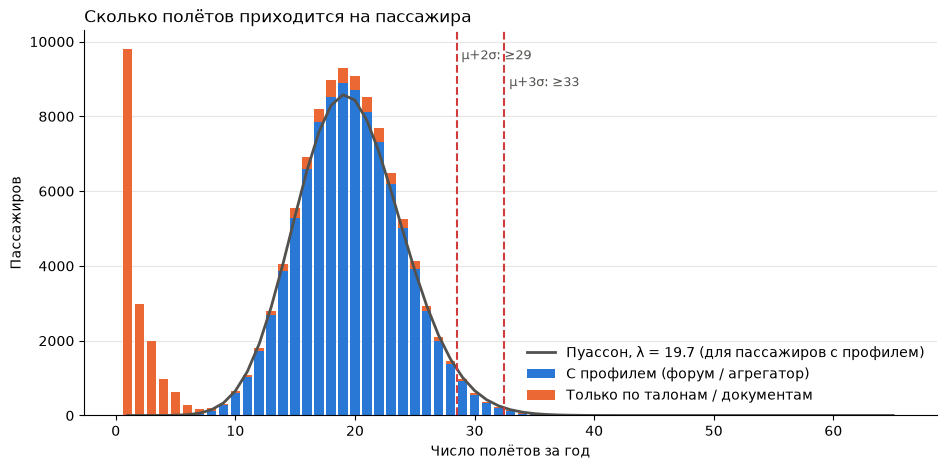

In [3]:
BLUE, ORANGE, INK, MUTED, RED = '#2a78d6', '#eb6834', '#52514e', '#76756f', '#d03b3b'

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(k, dist['profile'], width=0.8, color=BLUE, label='С профилем (форум / агрегатор)')
ax.bar(k, dist['tickets'], width=0.8, bottom=dist['profile'], color=ORANGE, label='Только по талонам / документам')
ax.plot(k, dist['poisson'], color=INK, lw=2, label=f'Пуассон, λ = {lam:.1f} (для пассажиров с профилем)')
ymax = ax.get_ylim()[1]
for i, (t, name) in enumerate([(thr2, 'μ+2σ'), (thr3, 'μ+3σ')]):
    ax.axvline(t - 0.5, color=RED, lw=1.5, ls='--')
    ax.text(t - 0.1, ymax * (0.95 - 0.07 * i), f'{name}: ≥{t}', color=INK, fontsize=9, va='top')
ax.set_xlabel('Число полётов за год')
ax.set_ylabel('Пассажиров')
ax.set_title('Сколько полётов приходится на пассажира', loc='left')
ax.grid(axis='y', color='#e6e5e0'); ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False)
plt.show()

In [4]:
tail = pd.DataFrame({
    'наблюдается (≥k)': dist['profile'][::-1].cumsum()[::-1],
    'ожидается по Пуассону (≥k)': dist['poisson'][::-1].cumsum()[::-1].round(1),
})
tail['отношение'] = (tail.iloc[:, 0] / tail.iloc[:, 1]).round(2)
tail['доля пассажиров с профилем'] = (tail.iloc[:, 0] / N).map('{:.2%}'.format)
tail.loc[24:42]

,наблюдается (≥k),ожидается по Пуассону (≥k),отношение,доля пассажиров с профилем
n_trips,,,,
24,17373,18121.3,0.96,18.25%
25,12357,13181.5,0.94,12.98%
26,8442,9297.0,0.91,8.87%
27,5659,6359.8,0.89,5.94%
28,3657,4221.1,0.87,3.84%
29,2285,2719.5,0.84,2.40%
30,1374,1701.6,0.81,1.44%
31,814,1034.5,0.79,0.85%
32,472,611.5,0.77,0.50%


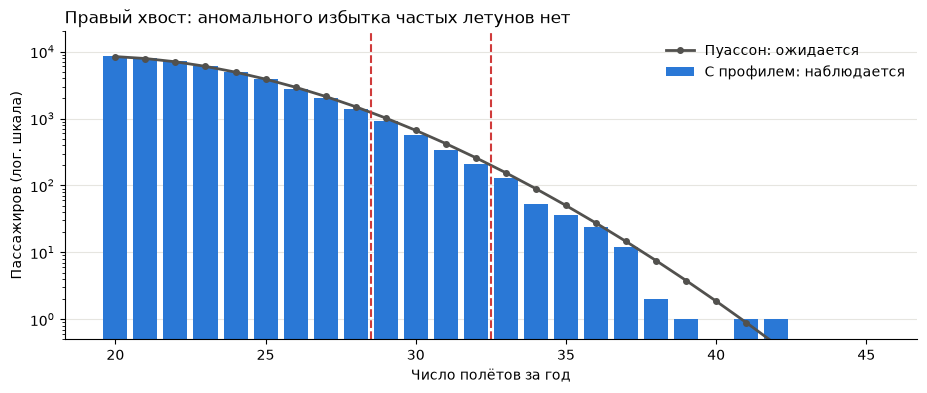

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
sel = dist.loc[20:45]
ax.bar(sel.index, sel['profile'], width=0.8, color=BLUE, label='С профилем: наблюдается')
ax.plot(sel.index, sel['poisson'], color=INK, lw=2, marker='o', ms=4, label='Пуассон: ожидается')
ax.set_yscale('log'); ax.set_ylim(0.5, 2e4)
ax.axvline(thr2 - 0.5, color=RED, lw=1.5, ls='--'); ax.axvline(thr3 - 0.5, color=RED, lw=1.5, ls='--')
ax.set_xlabel('Число полётов за год'); ax.set_ylabel('Пассажиров (лог. шкала)')
ax.set_title('Правый хвост: аномального избытка частых летунов нет', loc='left')
ax.grid(axis='y', color='#e6e5e0'); ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False)
plt.show()

In [6]:
rows = []
for name, t in [('μ+2σ', thr2), ('μ+3σ', thr3)]:
    n_prof = int((prof >= t).sum())
    n_tix = int(((pax.n_trips >= t) & pax.weak).sum())
    rows.append({'порог': f'{name}: ≥{t} полётов', 'с профилем': n_prof,
                 '% от пассажиров с профилем': f'{n_prof / N:.2%}',
                 '% от всех пассажиров с полётами': f'{n_prof / len(pax):.2%}',
                 'ожидается случайно': round(dist.loc[t:, 'poisson'].sum()),
                 'слабая идентификация (отдельно)': n_tix})
pd.DataFrame(rows)

,порог,с профилем,% от пассажиров с профилем,% от всех пассажиров с полётами,ожидается случайно,слабая идентификация (отдельно)
0,μ+2σ: ≥29 полётов,2285,2.40%,1.96%,2720,228
1,μ+3σ: ≥33 полётов,259,0.27%,0.22%,352,113
